# The Curse of Dimensionality and KNN: a tutorial

The first tutorial (`00_knn_tutorial.ipynb`) ended with a warning: add enough useless features and KNN's accuracy collapses toward a coin flip. This notebook explains **why**, from first principles. For each effect we will:

1. **derive it with math** (nothing beyond sums, expectations, variances and a little geometry),
2. **check the math numerically** with a simulation, and
3. **connect it to KNN**: what it does to neighbors, votes and accuracy.

By the end you should be able to explain, with formulas, why "nearest neighbor" can stop meaning anything in high dimensions, *and* why KNN still works on plenty of high-dimensional real data.

## Sections

| # | Section | The one-line idea |
|---|---|---|
| 0 | Setup | Libraries |
| 1 | What is the curse? | Notation, and a math toolkit (expectation, variance, the √d rule) |
| 2 | Space grows exponentially | To capture 1% of the data in 10-D, you need 63% of each axis |
| 3 | Where the volume lives | In high-d, volume is in the corners and near the surface |
| 4 | Neighbors move far away | Halving the nearest-neighbor distance needs 2^d times more data |
| 5 | Distance concentration | All distances become nearly equal: spread / mean ∝ 1/√d |
| 6 | What concentration does to KNN | Noise features drown the signal in distance comparisons, at rate 1/√m |
| 7 | Hubness | Some points become "everyone's neighbor" |
| 8 | The escape hatch: intrinsic dimension | Columns aren't the problem; noise is |
| 9 | Defenses in practice | Feature selection, PCA, and when each works |
| 10 | Summary | Formula cheat sheet and exercises |

## How to use this notebook

- **Run the cells in order.** Later sections reuse functions from earlier ones.
- Every section starts with an **objective**, then the **math**, then **code that checks the math**, then **what it means for KNN**.
- **Every line of code is commented.** The math is written in LaTeX; it renders when you run (or view) the markdown cells.
- The companion lab, `01_knn_high_dim.ipynb`, has you run related experiments yourself, predicting the results first. This notebook gives you the theory to interpret them.

## 0. Setup

**Objective:** Import the libraries and fix the random seed so every run gives the same numbers.

In [1]:
import numpy as np                                        # arrays and math
import matplotlib.pyplot as plt                           # plotting
from scipy.special import gammaln                         # log of the Gamma function: needed for ball volumes (Section 3)
from scipy.stats import norm, skew                        # normal distribution (Section 6), skewness (Section 7)
from scipy.spatial.distance import pdist                  # all pairwise distances within one set of points

from sklearn.datasets import make_moons, load_digits      # a synthetic 2-D dataset and a real 64-D image dataset
from sklearn.model_selection import train_test_split, cross_val_score   # data splitting and cross-validation
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors    # KNN classifier, and raw neighbor search
from sklearn.preprocessing import StandardScaler          # rescale features to mean 0, std 1
from sklearn.decomposition import PCA                     # principal component analysis
from sklearn.feature_selection import SelectKBest, f_classif   # keep the k features most related to the label
from sklearn.pipeline import make_pipeline                # chain preprocessing and a model into one estimator

np.set_printoptions(precision=4, suppress=True)           # 4 decimals, no scientific notation when printing arrays
SEED = 0                                                  # one seed for the whole notebook: results are reproducible

## 1. What is the curse of dimensionality?

**Objective:** Pin down the term, fix the notation, and collect the few math tools the rest of the notebook uses.

**The term.** Richard Bellman coined "the curse of dimensionality" in 1957 to describe how problems get exponentially harder as the number of variables grows. It isn't a single effect but a **family of related effects**, all caused by the geometry of high-dimensional space. Sections 2–7 go through them one at a time.

**Why KNN is especially exposed.** KNN has exactly one source of knowledge: the distance function. It never learns which features matter. So every geometric oddity of high-dimensional space reaches KNN directly through its distances.

### Notation

| Symbol | Meaning |
|---|---|
| $d$ | number of dimensions (features) |
| $n$ | number of data points |
| $x = (x_1, \dots, x_d)$ | one point: a vector of $d$ numbers |
| $\lVert x - y \rVert = \sqrt{\sum_{j=1}^d (x_j - y_j)^2}$ | Euclidean distance between $x$ and $y$ |
| $\mathbb{E}[Z]$, $\operatorname{Var}(Z)$ | expected value (long-run average) and variance of a random quantity $Z$ |
| $\operatorname{sd}(Z) = \sqrt{\operatorname{Var}(Z)}$ | standard deviation: the typical size of $Z$'s fluctuations |
| $U[0,1]$ | the uniform distribution on [0, 1]; "uniform in the cube" means every coordinate is independently $U[0,1]$ |
| $\mathcal{N}(0, 1)$ | the standard normal (Gaussian) distribution |

### The math toolkit

Almost every derivation below uses these three facts.

**Fact 1: expectations add.** For any random quantities, $\mathbb{E}[Z_1 + \dots + Z_d] = \mathbb{E}[Z_1] + \dots + \mathbb{E}[Z_d]$.

**Fact 2: variances of *independent* quantities add.** If $Z_1, \dots, Z_d$ are independent, $\operatorname{Var}(Z_1 + \dots + Z_d) = \operatorname{Var}(Z_1) + \dots + \operatorname{Var}(Z_d)$.

**Fact 3, the √d rule (a consequence of 1 and 2).** If $S = Z_1 + \dots + Z_d$ is a sum of $d$ independent terms that each have mean $\mu$ and variance $\sigma^2$, then

$$\mathbb{E}[S] = d\mu, \qquad \operatorname{sd}(S) = \sqrt{d}\,\sigma, \qquad \frac{\operatorname{sd}(S)}{\mathbb{E}[S]} = \frac{\sigma}{\mu}\cdot\frac{1}{\sqrt{d}}.$$

**The mean grows like $d$, but the spread only grows like $\sqrt{d}$**, so the spread *relative to the mean* shrinks like $1/\sqrt{d}$. A squared distance is exactly such a sum (one term per coordinate), so this one rule drives most of the curse. Keep it in mind.

The quick check below verifies Fact 3 by simulation.

In [2]:
rng = np.random.default_rng(SEED)                    # random number generator with the notebook's seed

for d in [1, 10, 100, 1000]:                         # four numbers of terms
    Z = rng.uniform(0, 1, size=(20_000, d))          # 20,000 repetitions, each with d independent U[0,1] terms
    S = Z.sum(axis=1)                                # add the d terms in each repetition: 20,000 sums
    # Theory: each U[0,1] term has mean 1/2 and variance 1/12, so E[S] = d/2 and sd(S) = sqrt(d/12)
    print(f"d={d:>4}:  mean {S.mean():8.2f} (theory {d/2:7.1f})  |  "
          f"sd {S.std():6.3f} (theory {np.sqrt(d/12):6.3f})  |  "
          f"sd/mean {S.std()/S.mean():.4f} (theory {np.sqrt(d/12)/(d/2):.4f})")

d=   1:  mean     0.50 (theory     0.5)  |  sd  0.288 (theory  0.289)  |  sd/mean 0.5724 (theory 0.5774)
d=  10:  mean     4.99 (theory     5.0)  |  sd  0.918 (theory  0.913)  |  sd/mean 0.1838 (theory 0.1826)
d= 100:  mean    50.02 (theory    50.0)  |  sd  2.877 (theory  2.887)  |  sd/mean 0.0575 (theory 0.0577)
d=1000:  mean   499.95 (theory   500.0)  |  sd  9.118 (theory  9.129)  |  sd/mean 0.0182 (theory 0.0183)


The mean grows 1000× from `d = 1` to `d = 1000`; the spread grows only about 32× ($\sqrt{1000}$). Relative to its mean, the sum becomes almost a constant.

## 2. Space grows exponentially

**Objective:** See how quickly high-dimensional space becomes empty, and what that means for the size of a "neighborhood".

### The math

Take $n$ points uniform in the unit cube $[0,1]^d$. Around a query point, build a small sub-cube with edge length $e$ (along every axis). Its volume is $e^d$, so it contains, on average, a fraction $e^d$ of the data.

Suppose we want the neighborhood to contain a fraction $r$ of the data (say $r = 1\%$, to get 10 neighbors out of 1000 points). Solve $e^d = r$:

$$\boxed{\,e_d(r) = r^{1/d}\,}$$

| | $d = 1$ | $d = 2$ | $d = 3$ | $d = 10$ | $d = 100$ |
|---|---|---|---|---|---|
| $e_d(0.01)$ | 0.01 | 0.10 | 0.22 | 0.63 | 0.955 |

In 10 dimensions, a "neighborhood" holding just 1% of the data must span **63% of the range of every feature**. In 100 dimensions, 95.5%. Such a neighborhood isn't local at all, yet KNN treats its contents as "similar" points. (This example is from Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning*, §2.5.)

**The same fact, seen from the data side:** cut every axis into 10 bins. That gives $10^d$ cells. With $d = 10$ there are ten billion cells, so any realistic dataset leaves almost all of them empty.

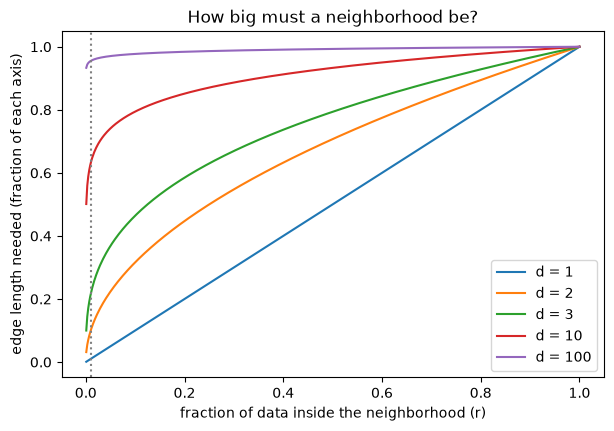

Edge length needed to capture 1% of the data:
  d =   1: 0.010
  d =   2: 0.100
  d =   3: 0.215
  d =  10: 0.631
  d = 100: 0.955


In [3]:
r = np.linspace(0.001, 1, 500)                        # fractions of the data from 0.1% to 100%

fig, ax = plt.subplots(figsize=(7, 4.5))              # one plot
for d in [1, 2, 3, 10, 100]:                          # one curve per dimension
    ax.plot(r, r ** (1 / d), label=f"d = {d}")        # edge length e = r^(1/d) needed to capture fraction r
ax.axvline(0.01, color="gray", ls=":")                # mark r = 1%
ax.set(xlabel="fraction of data inside the neighborhood (r)",
       ylabel="edge length needed (fraction of each axis)",
       title="How big must a neighborhood be?")
ax.legend()
plt.show()

print("Edge length needed to capture 1% of the data:")
for d in [1, 2, 3, 10, 100]:                          # the table from the markdown above
    print(f"  d = {d:>3}: {0.01 ** (1 / d):.3f}")

**Check by simulation:** in 10-D, a sub-cube with edge $0.01^{1/10} \approx 0.631$ should contain about 1% of uniform points.

In [4]:
rng = np.random.default_rng(SEED)                    # fresh generator
d = 10                                               # 10 dimensions
X = rng.uniform(0, 1, size=(200_000, d))             # 200,000 uniform points in the 10-D unit cube
e = 0.01 ** (1 / d)                                  # the predicted edge length, about 0.631
inside = np.all(X < e, axis=1)                       # True where ALL 10 coordinates are below e, i.e. inside [0, e]^10
print(f"edge length {e:.3f} covers {e:.0%} of each axis, but contains {inside.mean():.2%} of the points")

edge length 0.631 covers 63% of each axis, but contains 1.02% of the points


**What it means for KNN:** KNN assumes the `k` nearest points are *local*, close enough that the label shouldn't change much across them. In high dimensions, even a handful of neighbors spans most of the feature space, so the locality assumption fails unless the dataset is astronomically large.

## 3. Where the volume lives: corners and shells

**Objective:** Build intuition for high-dimensional shapes. Two results surprise almost everyone: a ball takes up a vanishing share of its surrounding cube, and almost all of a ball's volume sits in a thin layer near its surface.

### The ball inside the cube

The volume of a $d$-dimensional ball of radius $\rho$ is

$$V_d(\rho) = \frac{\pi^{d/2}}{\Gamma\!\left(\frac{d}{2}+1\right)}\,\rho^d,$$

where $\Gamma$ is the Gamma function, which extends the factorial ($\Gamma(m+1) = m!$). Sanity checks: $d = 2$ gives $\pi\rho^2$ (a disk) and $d = 3$ gives $\tfrac{4}{3}\pi\rho^3$ (a sphere).

Put the largest possible ball inside the unit cube: radius $\rho = 1/2$, touching the middle of every face. The cube has volume 1, so the share of the cube inside the ball is just $V_d(1/2)$:

| $d$ | 2 | 3 | 5 | 10 | 20 |
|---|---|---|---|---|---|
| share of cube inside ball | 78.5% | 52.4% | 16.4% | 0.25% | 0.000002% |

The factorial-like $\Gamma$ in the denominator eventually crushes the $\pi^{d/2}$ in the numerator. **In high dimensions, almost all of a cube's volume is in its corners**, far from the center. The cube's corners are at distance $\sqrt{d}/2$ from the center, while its faces are only $1/2$ away, so the corners get relatively farther and farther out as $d$ grows.

*(We compute $V_d$ with `gammaln`, the logarithm of $\Gamma$, because $\Gamma$ itself overflows for large arguments.)*

In [5]:
def log_ball_volume(d, radius):
    # log V_d(radius) = (d/2) log(pi) + d log(radius) - log Gamma(d/2 + 1); logs avoid overflow for large d
    return (d / 2) * np.log(np.pi) + d * np.log(radius) - gammaln(d / 2 + 1)

rng = np.random.default_rng(SEED)                              # fresh generator
print(f"{'d':>3} {'formula':>12} {'simulation':>12}")         # table header
for d in [1, 2, 3, 5, 10, 20]:                                 # dimensions to check
    exact = np.exp(log_ball_volume(d, 0.5))                    # share of the unit cube inside the inscribed ball
    X = rng.uniform(0, 1, size=(200_000, d))                   # random points in the cube
    inside = np.linalg.norm(X - 0.5, axis=1) <= 0.5            # True if within distance 1/2 of the center (0.5, ..., 0.5)
    print(f"{d:>3} {exact:>12.6f} {inside.mean():>12.6f}")     # formula vs fraction of simulated points inside

  d      formula   simulation
  1     1.000000     1.000000
  2     0.785398     0.784880
  3     0.523599     0.521520
  5     0.164493     0.163190
 10     0.002490     0.002585
 20     0.000000     0.000000


At `d = 20` the simulation finds essentially no points in the ball, even out of 200,000. That isn't a bug: the true share is about 2 in 100 million.

### Thin shells hold everything

Take a ball of radius 1 and peel off a thin outer layer of thickness $\varepsilon$. The inner ball has radius $1 - \varepsilon$, so its share of the volume is $(1-\varepsilon)^d$ (volume scales like $\rho^d$). The outer shell therefore holds

$$\text{share in shell} = 1 - (1 - \varepsilon)^d \;\xrightarrow{d \to \infty}\; 1.$$

With $\varepsilon = 0.01$ (the outer 1% of the radius): 2% of the volume in 2-D, 63% in 100-D, and 99.996% in 1000-D.

### The Gaussian "soap bubble"

The same thing happens for Gaussian data. If $x \sim \mathcal{N}(0, I_d)$ (every coordinate an independent standard normal), then $\lVert x \rVert^2 = \sum_j x_j^2$ is a sum of $d$ independent terms, each with mean 1 and variance 2. By the √d rule:

$$\mathbb{E}\lVert x\rVert^2 = d, \qquad \operatorname{sd}\big(\lVert x\rVert^2\big) = \sqrt{2d}.$$

Taking square roots (for large $d$): $\lVert x \rVert \approx \sqrt{d}$, with a spread of about $\sqrt{2d} / (2\sqrt{d}) = 1/\sqrt{2} \approx 0.71$, a **constant** that doesn't grow with $d$. So high-dimensional Gaussian points don't cluster at the center, where the density is highest. They sit on a thin shell of radius $\approx\sqrt{d}$. Almost no point is near the "typical" center.

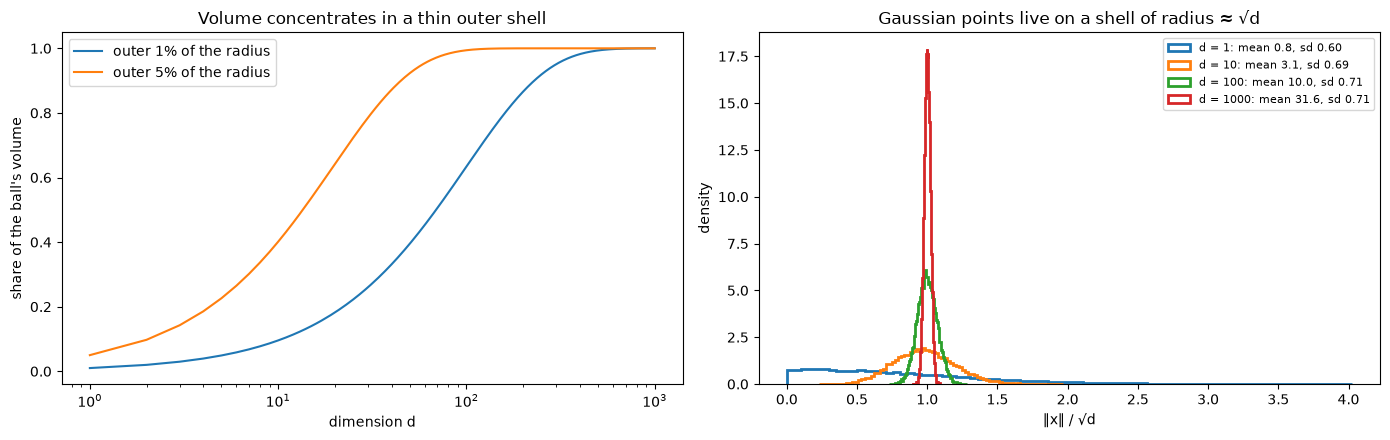

In [6]:
rng = np.random.default_rng(SEED)                                  # fresh generator
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))                  # two panels

eps_values = [0.01, 0.05]                                          # two shell thicknesses
d_grid = np.arange(1, 1001)                                        # dimensions 1 to 1000
for eps in eps_values:                                             # one curve per thickness
    axes[0].plot(d_grid, 1 - (1 - eps) ** d_grid,                  # share of volume in the outer shell
                 label=f"outer {eps:.0%} of the radius")
axes[0].set(xscale="log", xlabel="dimension d", ylabel="share of the ball's volume",
            title="Volume concentrates in a thin outer shell")
axes[0].legend()

for d in [1, 10, 100, 1000]:                                       # four dimensions
    norms = np.linalg.norm(rng.standard_normal((20_000, d)), axis=1)   # lengths of 20,000 Gaussian vectors
    axes[1].hist(norms / np.sqrt(d), bins=80, histtype="step", lw=2, density=True,   # rescaled by sqrt(d)
                 label=f"d = {d}: mean {norms.mean():.1f}, sd {norms.std():.2f}")
axes[1].set(xlabel="‖x‖ / √d", ylabel="density",
            title="Gaussian points live on a shell of radius ≈ √d")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In the right panel, look at the legend: the mean length grows like $\sqrt{d}$ (about 0.8, 3.1, 10, 31.6), while the sd settles near 0.71 from `d = 10` on, exactly as derived (the large-$d$ approximation doesn't apply at `d = 1`). After rescaling by $\sqrt{d}$, the distribution collapses onto a spike at 1.

**What it means for KNN:** in high dimensions, data points live "at the edges", near corners and surfaces, all at roughly the same distance from the center. That uniformity is the first hint of what Section 5 makes precise: points end up roughly equidistant from each other, too.

## 4. Neighbors move far away

**Objective:** Quantify how far the *nearest* neighbor is, and how much data it takes to keep it close.

### The math

With $n$ points uniform in the unit cube, the expected number of points within distance $\rho$ of a query is about $n \cdot V_d(\rho)$ (ignoring edge effects). The nearest neighbor sits roughly where that count reaches 1:

$$n\, V_d(1)\, \rho_{\text{NN}}^d \approx 1 \quad\Longrightarrow\quad \rho_{\text{NN}} \approx \big(n\,V_d(1)\big)^{-1/d} \;\propto\; n^{-1/d}.$$

The exponent $-1/d$ is the problem. To **halve** the nearest-neighbor distance you need $2^d$ times more data: twice as much data in 1-D, a thousand times in 10-D, $10^{30}$ times in 100-D.

The simpler cube version from Section 2 tells the same story: for a sub-cube of edge 0.1 around the query to contain one point on average, you need $n \cdot 0.1^d = 1$, i.e. **$n = 10^d$ points**.

### Near vs. typical

The absolute NN distance isn't the whole story; what matters is how it compares with the distance to a *typical* point. The cell below measures both, using separate query points (so a point is never its own neighbor).

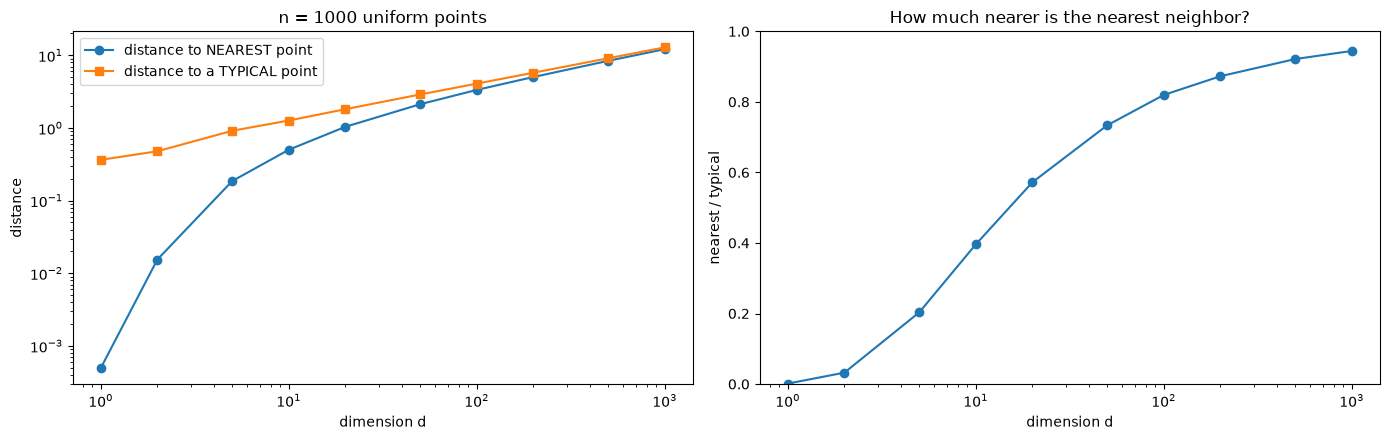

Points needed for a sub-cube of edge 0.1 to hold one point on average (n = 10^d):
  d =  1: 1e+01
  d =  2: 1e+02
  d =  3: 1e+03
  d =  5: 1e+05
  d = 10: 1e+10
  d = 20: 1e+20


In [7]:
rng = np.random.default_rng(SEED)                        # fresh generator
DIMS = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]        # dimensions to test
n, n_queries = 1000, 200                                 # data points, and separate query points

nn_dist, typical_dist = [], []                           # mean nearest-neighbor distance; mean distance to any point
for d in DIMS:                                           # for each dimension...
    X = rng.uniform(0, 1, size=(n, d))                   # ...n data points in the unit cube
    Q = rng.uniform(0, 1, size=(n_queries, d))           # ...and fresh query points from the same distribution
    dist_nn, _ = NearestNeighbors(n_neighbors=1).fit(X).kneighbors(Q)   # distance from each query to its nearest data point
    nn_dist.append(dist_nn.mean())                       # average over queries
    typical_dist.append(np.linalg.norm(X[None, :, :] - Q[:20, None, :], axis=2).mean())   # mean distance from 20 queries to all points

nn_dist, typical_dist = np.array(nn_dist), np.array(typical_dist)   # lists -> arrays

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(DIMS, nn_dist, "o-", label="distance to NEAREST point")
axes[0].plot(DIMS, typical_dist, "s-", label="distance to a TYPICAL point")
axes[0].set(xscale="log", yscale="log", xlabel="dimension d", ylabel="distance",
            title=f"n = {n} uniform points")
axes[0].legend()
axes[1].plot(DIMS, nn_dist / typical_dist, "o-")                # the ratio we actually care about
axes[1].set(xscale="log", ylim=(0, 1), xlabel="dimension d", ylabel="nearest / typical",
            title="How much nearer is the nearest neighbor?")
plt.tight_layout()
plt.show()

print("Points needed for a sub-cube of edge 0.1 to hold one point on average (n = 10^d):")
for d in [1, 2, 3, 5, 10, 20]:
    print(f"  d = {d:>2}: {10.0 ** d:.0e}")

**How to read it:** in low dimensions, the nearest neighbor is *much* closer than a typical point (ratio near 0). As $d$ grows, the ratio climbs toward 1: the "nearest" neighbor is barely nearer than a random point.

**What it means for KNN:** KNN's whole premise is that the nearest points are special. When the nearest point is only slightly closer than an average one, the neighbors KNN picks are barely more relevant than random picks. And no realistic amount of data fixes it, because the data needed grows exponentially in $d$.

## 5. Distance concentration

**Objective:** Derive exactly how the spread of distances shrinks relative to their size, and confirm the formulas numerically. This is the central result of the notebook.

### The math, step by step

Let $x$ and $y$ be independent and uniform in $[0,1]^d$. Write the squared distance as a sum over coordinates:

$$D^2 = \lVert x - y\rVert^2 = \sum_{j=1}^{d} \underbrace{(x_j - y_j)^2}_{W_j}.$$

The terms $W_j$ are independent (each uses different coordinates) and identically distributed. We need their mean and variance. Let $U = x_j - y_j$, the difference of two independent $U[0,1]$ numbers. $U$ has a triangular density $1 - |u|$ on $[-1, 1]$, so:

$$\mathbb{E}[U^2] = 2\int_0^1 u^2 (1-u)\,du = 2\left(\tfrac13 - \tfrac14\right) = \tfrac16, \qquad \mathbb{E}[U^4] = 2\int_0^1 u^4(1-u)\,du = 2\left(\tfrac15 - \tfrac16\right) = \tfrac1{15}.$$

So each term has

$$\mu = \mathbb{E}[W_j] = \tfrac16, \qquad \sigma^2 = \operatorname{Var}(W_j) = \mathbb{E}[U^4] - \mathbb{E}[U^2]^2 = \tfrac1{15} - \tfrac1{36} = \tfrac{7}{180}.$$

By the √d rule:

$$\mathbb{E}[D^2] = \frac{d}{6}, \qquad \operatorname{sd}(D^2) = \sqrt{\frac{7d}{180}}.$$

**From $D^2$ to $D$.** For large $d$, $D^2$ is tightly packed around its mean $m = d/6$. A square root changes small deviations like this (a first-order Taylor expansion, also called the *delta method*): $\sqrt{m + \delta} \approx \sqrt{m} + \frac{\delta}{2\sqrt{m}}$. So

$$\mathbb{E}[D] \approx \sqrt{\frac{d}{6}}, \qquad \operatorname{sd}(D) \approx \frac{\operatorname{sd}(D^2)}{2\sqrt{d/6}} = \frac12\sqrt{\frac{7\cdot 6}{180}} \approx \mathbf{0.2415} \quad\text{(a constant!)}$$

$$\boxed{\;\frac{\operatorname{sd}(D)}{\mathbb{E}[D]} \approx \frac{0.5916}{\sqrt{d}} \;\xrightarrow{d\to\infty}\; 0\;}$$

**In words:** typical distances grow like $\sqrt{d}$, but how much they *differ from one another* stays fixed at about 0.24. So relative to their size, all distances become the same.

### From spread to "nearest vs. farthest"

A query has $n$ distances to the data points. Roughly speaking, the smallest and largest of them sit a few standard deviations below and above the mean, with the number of standard deviations growing slowly with $n$ (about $\sqrt{2\ln n}$ for bell-shaped distributions). So

$$\frac{D_{\max} - D_{\min}}{D_{\min}} \;\approx\; \frac{\text{(a few)}\times\operatorname{sd}(D)}{\mathbb{E}[D]} \;\propto\; \frac{1}{\sqrt{d}} \;\to\; 0.$$

This is the theorem of **Beyer, Goldstein, Ramakrishnan & Shaft (1999), "When Is 'Nearest Neighbor' Meaningful?"**: if the relative spread of the distances goes to zero, then the ratio of the farthest to the nearest distance goes to 1, for *any* fixed number of points. Our derivation shows the condition holds for uniform data with rate $1/\sqrt{d}$, and the same argument works for any distribution with independent coordinates.

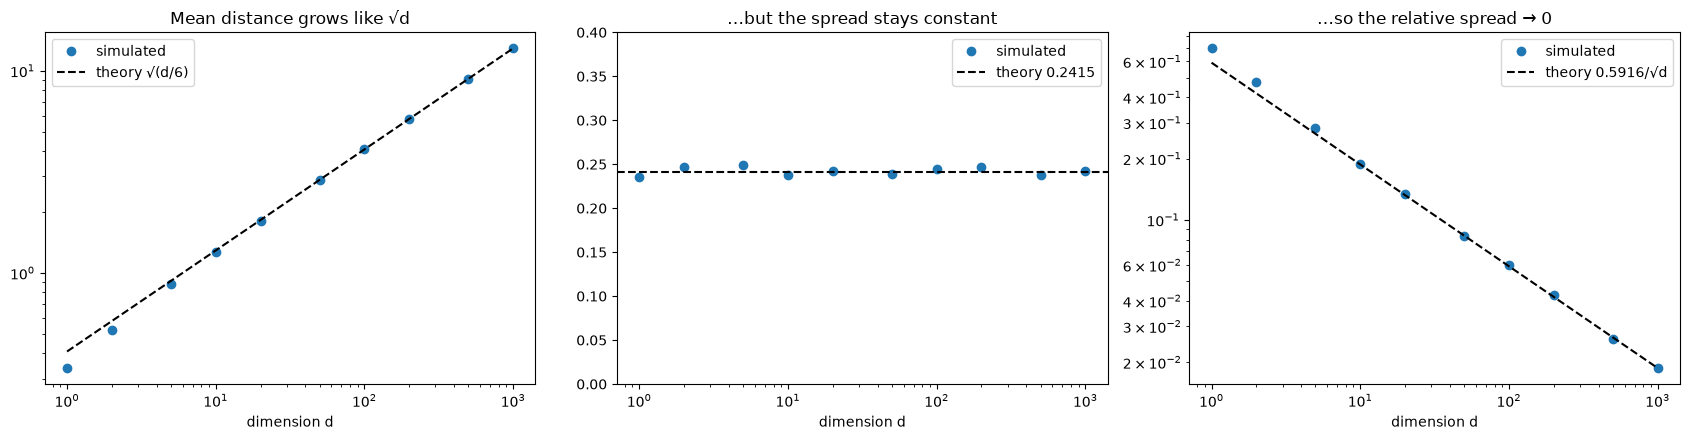

In [8]:
rng = np.random.default_rng(SEED)                             # fresh generator
n_pairs = 5_000                                               # independent pairs (x, y) per dimension

mean_D, sd_D = [], []                                         # empirical mean and sd of the distance
for d in DIMS:                                                # for each dimension...
    x = rng.uniform(0, 1, size=(n_pairs, d))                  # ...5000 random points x
    y = rng.uniform(0, 1, size=(n_pairs, d))                  # ...and 5000 independent partners y
    D = np.linalg.norm(x - y, axis=1)                         # 5000 distances, one per pair
    mean_D.append(D.mean())                                   # store the average distance
    sd_D.append(D.std())                                      # store the spread of the distances
mean_D, sd_D = np.array(mean_D), np.array(sd_D)               # lists -> arrays
d_arr = np.array(DIMS, dtype=float)                           # dimensions as floats, for the theory curves

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(DIMS, mean_D, "o", label="simulated")
axes[0].plot(d_arr, np.sqrt(d_arr / 6), "k--", label="theory √(d/6)")        # E[D] ≈ sqrt(d/6)
axes[0].set(xscale="log", yscale="log", title="Mean distance grows like √d")
axes[1].plot(DIMS, sd_D, "o", label="simulated")
axes[1].axhline(0.2415, color="k", ls="--", label="theory 0.2415")           # sd(D) ≈ constant
axes[1].set(xscale="log", ylim=(0, 0.4), title="…but the spread stays constant")
axes[2].plot(DIMS, sd_D / mean_D, "o", label="simulated")
axes[2].plot(d_arr, 0.5916 / np.sqrt(d_arr), "k--", label="theory 0.5916/√d")  # relative spread
axes[2].set(xscale="log", yscale="log", title="…so the relative spread → 0")
for ax in axes:                                               # shared labeling
    ax.set_xlabel("dimension d")
    ax.legend()
plt.tight_layout()
plt.show()

The approximations are rough at very small `d` (the Taylor step assumes $D^2$ is tightly packed, which it isn't in 1-D or 2-D). From about `d = 10` on, simulation and theory agree closely.

**Now the KNN-relevant version:** relative contrast $(D_{\max} - D_{\min})/D_{\min}$ from one query to $n = 1000$ points, compared with the $1/\sqrt{d}$ scaling. The theory curve is anchored to the measurement at `d = 100`, so it tests the *shape* (slope) of the prediction, not its constant.

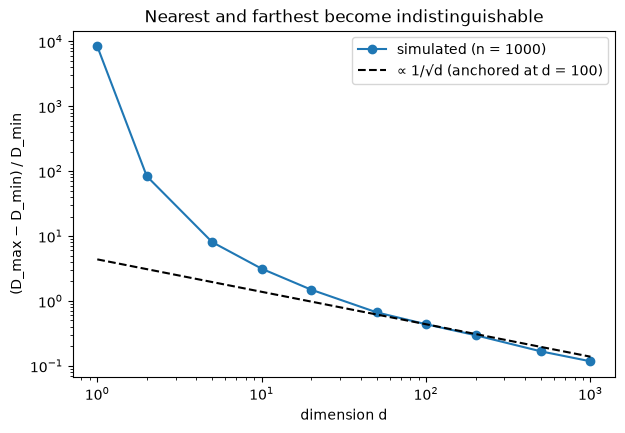

In [9]:
rng = np.random.default_rng(SEED)                                 # fresh generator
contrast = []                                                     # mean relative contrast per dimension
for d in DIMS:
    vals = []                                                     # one value per repetition
    for _ in range(10):                                           # 10 repetitions to smooth out randomness
        X = rng.uniform(0, 1, size=(1000, d))                     # 1000 data points
        q = rng.uniform(0, 1, size=d)                             # one query point
        D = np.linalg.norm(X - q, axis=1)                         # distances from the query to all data points
        vals.append((D.max() - D.min()) / D.min())                # relative contrast
    contrast.append(np.mean(vals))                                # average over repetitions
contrast = np.array(contrast)                                     # list -> array

anchor = DIMS.index(100)                                          # position of d = 100 in the list
theory = contrast[anchor] * np.sqrt(100 / d_arr)                  # c / sqrt(d), with c chosen to match at d = 100

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(DIMS, contrast, "o-", label="simulated (n = 1000)")
ax.plot(d_arr, theory, "k--", label="∝ 1/√d (anchored at d = 100)")
ax.set(xscale="log", yscale="log", xlabel="dimension d", ylabel="(D_max − D_min) / D_min",
       title="Nearest and farthest become indistinguishable")
ax.legend()
plt.show()

For large `d` the simulated contrast follows the $1/\sqrt{d}$ line. In low dimensions the contrast is enormous, because the nearest point can be extremely close, so the asymptotic formula doesn't apply there.

**What it means for KNN:** KNN ranks points by distance and keeps the top `k`. When every distance is within a few percent of every other, that ranking is decided by tiny, essentially random fluctuations. On data with no structure, the "k nearest neighbors" become an almost arbitrary subset.

## 6. What concentration does to KNN: signal drowned by noise

**Objective:** Real data isn't pure noise; it has *some* features that matter. Show mathematically how irrelevant features drown out the relevant ones in KNN's distance comparisons, and confirm that this predicts KNN's accuracy.

### Setup

- **1 signal feature:** class 1 points have $s \sim \mathcal{N}(+\mu, 1)$ and class 0 points have $s \sim \mathcal{N}(-\mu, 1)$, with $\mu = 1.5$.
- **$m$ noise features:** each $\mathcal{N}(0, 1)$, independent of the label. Note they have the **same scale** as the signal's within-class spread, so noise can't win just by being bigger.

### The question KNN implicitly asks

Take a query $q$, a random point $a$ from the **same** class, and a random point $b$ from the **other** class. KNN works when, typically, $a$ is nearer than $b$. Define

$$\Delta = \lVert q - b\rVert^2 - \lVert q - a\rVert^2 \qquad (\Delta > 0 \iff \text{the same-class point is nearer}).$$

The probability $P(\Delta > 0)$ measures how well distance separates the classes. 1 is perfect, 0.5 is useless. (It's the "AUC" of distance as a same-class detector.)

### Splitting $\Delta$ into signal and noise

Squared distances add over coordinates, so $\Delta = \Delta_{\text{signal}} + \Delta_{\text{noise}}$.

**Signal part:** depends only on the signal coordinate. Its mean $g = \mathbb{E}[\Delta_\text{signal}] > 0$ is the "gap" that makes KNN work; its variance $v_0$ is some fixed number. **Neither depends on $m$.**

**Noise part:** for one noise coordinate, with $q_j, a_j, b_j$ independent $\mathcal{N}(0,1)$:

$$(q_j - b_j)^2 - (q_j - a_j)^2 = b_j^2 - a_j^2 - 2q_j(b_j - a_j).$$

- Mean: $\mathbb{E}[b_j^2] - \mathbb{E}[a_j^2] - 2\,\mathbb{E}[q_j]\,\mathbb{E}[b_j - a_j] = 1 - 1 - 0 = 0$. Noise favors neither point.
- Variance: $\operatorname{Var}(b_j^2 - a_j^2) = 2 + 2 = 4$ (a squared standard normal has variance 2), and $\operatorname{Var}(2q_j(b_j-a_j)) = 4\cdot\mathbb{E}[q_j^2]\cdot\mathbb{E}[(b_j-a_j)^2] = 4\cdot 1\cdot 2 = 8$. The two pieces are uncorrelated (any cross term contains an odd power of the zero-mean $q_j$), so the total variance is $4 + 8 = \mathbf{12}$.

Summing $m$ independent noise coordinates (Facts 1 and 2): $\mathbb{E}[\Delta_\text{noise}] = 0$ and $\operatorname{Var}(\Delta_\text{noise}) = 12m$.

### The result

$$\Delta \text{ has mean } g \text{ and variance } v_0 + 12m, \qquad\text{so}\qquad P(\Delta > 0) \approx \Phi\!\left(\frac{g}{\sqrt{v_0 + 12m}}\right),$$

where $\Phi$ is the standard normal CDF (treating $\Delta$ as roughly bell-shaped). The quantity inside $\Phi$ is a **signal-to-noise ratio for distance comparisons**. The signal $g$ is fixed while the noise grows like $\sqrt{m}$, so

$$\boxed{\;\text{distance SNR} \;\propto\; \frac{1}{\sqrt{m}} \quad\Longrightarrow\quad P(\text{same-class point is nearer}) \to \tfrac12\;}$$

Every irrelevant feature adds variance to every comparison and nothing to the gap. Below, we measure $g$ and $v_0$ at $m = 0$ only, then use the formula to **predict** the curve for all $m$, and compare with simulation.

In [10]:
MU = 1.5                                                     # class means at +MU and -MU on the signal feature

def make_points(y, m, rng):
    # One point per label in y: column 0 is the signal feature, columns 1..m are pure noise. Shape (len(y), 1+m).
    signal = rng.normal(np.where(y == 1, MU, -MU), 1.0)      # signal ~ N(+MU, 1) for class 1, N(-MU, 1) for class 0
    noise = rng.standard_normal((len(y), m))                 # m columns of N(0, 1) noise, unrelated to y
    return np.column_stack([signal, noise])                  # glue signal and noise side by side

def make_signal_noise(n, m, rng):
    # A labeled dataset of n points: random labels, then points generated for those labels.
    y = rng.integers(0, 2, size=n)                           # random labels, 0 or 1, about half each
    return make_points(y, m, rng), y                         # features and labels

def sample_delta(m, n_triples, rng):
    # For many (query, same-class a, other-class b) triples, return Delta = ||q-b||^2 - ||q-a||^2.
    yq = rng.integers(0, 2, size=n_triples)                  # the class of each query
    q = make_points(yq, m, rng)                              # the queries
    same = make_points(yq, m, rng)                           # for each query, a fresh point from its OWN class (a)
    other = make_points(1 - yq, m, rng)                      # and a fresh point from the OTHER class (b)
    return ((q - other) ** 2).sum(axis=1) - ((q - same) ** 2).sum(axis=1)   # Delta for every triple

rng = np.random.default_rng(SEED)                            # fresh generator
delta0 = sample_delta(0, 200_000, rng)                       # m = 0: signal only
g, v0 = delta0.mean(), delta0.var()                          # the gap g and the signal variance v0, MEASURED at m = 0
print(f"measured at m = 0:  gap g = {g:.2f},  signal variance v0 = {v0:.2f}")

measured at m = 0:  gap g = 8.99,  signal variance v0 = 84.48


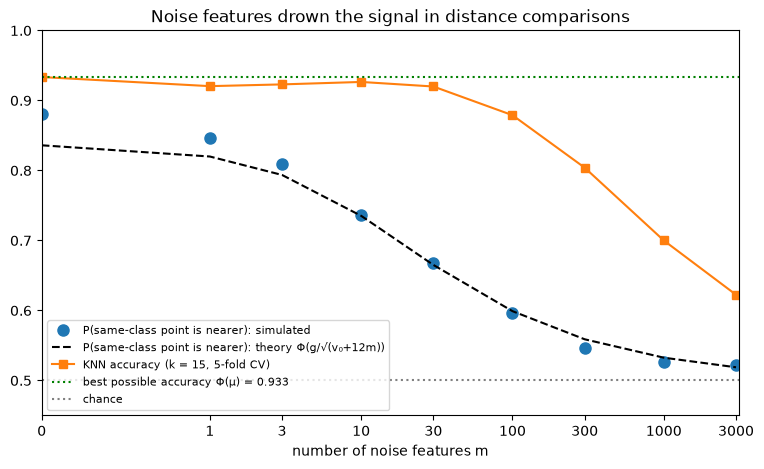

m =    0:  P simulated 0.881 | P theory 0.836 | KNN accuracy 0.933
m =    1:  P simulated 0.847 | P theory 0.820 | KNN accuracy 0.920
m =    3:  P simulated 0.809 | P theory 0.794 | KNN accuracy 0.923
m =   10:  P simulated 0.737 | P theory 0.735 | KNN accuracy 0.927
m =   30:  P simulated 0.668 | P theory 0.665 | KNN accuracy 0.920
m =  100:  P simulated 0.597 | P theory 0.599 | KNN accuracy 0.879
m =  300:  P simulated 0.546 | P theory 0.559 | KNN accuracy 0.804
m = 1000:  P simulated 0.526 | P theory 0.533 | KNN accuracy 0.700
m = 3000:  P simulated 0.522 | P theory 0.519 | KNN accuracy 0.622


In [11]:
M_VALUES = [0, 1, 3, 10, 30, 100, 300, 1000, 3000]           # numbers of noise features to test
rng = np.random.default_rng(SEED + 1)                        # a different stream from the previous cell

p_sim, p_theory, knn_acc = [], [], []                        # simulated P(Delta>0), predicted P(Delta>0), KNN accuracy
for m in M_VALUES:
    p_sim.append((sample_delta(m, 4_000, rng) > 0).mean())   # fraction of triples where the same-class point is nearer
    p_theory.append(norm.cdf(g / np.sqrt(v0 + 12 * m)))      # prediction: Phi(g / sqrt(v0 + 12m))
    X, y = make_signal_noise(2000, m, rng)                   # a classification dataset with m noise features
    knn_acc.append(cross_val_score(KNeighborsClassifier(n_neighbors=15), X, y, cv=5).mean())   # KNN accuracy, 5-fold CV

bayes = norm.cdf(MU)                                         # best possible accuracy using the signal alone: Phi(MU)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(M_VALUES, p_sim, "o", ms=8, label="P(same-class point is nearer): simulated")
ax.plot(M_VALUES, p_theory, "k--", label="P(same-class point is nearer): theory Φ(g/√(v₀+12m))")
ax.plot(M_VALUES, knn_acc, "s-", label="KNN accuracy (k = 15, 5-fold CV)")
ax.axhline(bayes, color="green", ls=":", label=f"best possible accuracy Φ(μ) = {bayes:.3f}")
ax.axhline(0.5, color="gray", ls=":", label="chance")
ax.set_xscale("symlog", linthresh=1)                         # symlog: log-like axis that can still show m = 0
ax.set_xticks(M_VALUES, labels=[str(m) for m in M_VALUES])   # label the tested values
ax.set_xlim(left=0)
ax.set(ylim=(0.45, 1.0), xlabel="number of noise features m",
       title="Noise features drown the signal in distance comparisons")
ax.legend(fontsize=8, loc="lower left")
plt.show()

for m, ps, pt, acc in zip(M_VALUES, p_sim, p_theory, knn_acc):   # the numbers behind the plot
    print(f"m = {m:>4}:  P simulated {ps:.3f} | P theory {pt:.3f} | KNN accuracy {acc:.3f}")

**How to read it:**
- **Theory vs. simulation (dots vs. dashes):** from about $m = 10$ on, the curve built from just two numbers measured at $m = 0$ tracks the simulation closely. That's the $1/\sqrt{m}$ law at work. At small $m$ the formula is off by a few points because it assumes $\Delta$ is bell-shaped, and the signal part (a difference of squared normals) is skewed. As $m$ grows, $\Delta$ is increasingly a sum of many independent noise terms, which the **central limit theorem** makes bell-shaped, so the approximation gets better exactly where it matters.
- **KNN accuracy (squares) sits well above the probability, but follows the same trend.** The probability compares *one random* same-class point with *one random* other-class point. KNN does better than that in two ways: it keeps only the *nearest* 15 of about 1600 training points (the extreme tail, where the signal's edge is concentrated), and then takes a majority vote, which turns a small per-neighbor edge into a larger edge for the decision. Both amplify the edge, but they can't create one. As the probability sinks toward 0.5 there is less and less edge to amplify, and KNN's accuracy heads toward chance too, just later in $m$.
- **The green line** is what's achievable from the signal feature alone. The signal never went anywhere; KNN just can't find it among the noise.

**Why don't all models suffer like this?** A model like logistic regression learns a **weight per feature**. It can drive the noise features' weights toward zero and effectively ignore them. KNN can't: every feature enters the distance with weight 1. (The lab notebook, Part 2, compares the two directly.)

## 7. Hubness: some points become everyone's neighbor

**Objective:** Understand a subtler effect: in high dimensions, the "k nearest neighbor" relation becomes extremely lopsided.

**The k-occurrence** $N_k(x)$ of a point $x$ is how many other points have $x$ among their $k$ nearest neighbors. Every point has exactly $k$ neighbors, so the $N_k$ values sum to $nk$ and **their mean is always exactly $k$**. Only the *shape* of their distribution can change.

### The math: why points near the center are "closer to everyone"

Let the data have mean $\bar{\mu}$. For a fixed point $x$ and a random data point $y$, expand the squared distance around the mean:

$$\lVert x - y\rVert^2 = \lVert (x - \bar\mu) - (y - \bar\mu)\rVert^2 = \lVert x - \bar\mu\rVert^2 - 2\,(x-\bar\mu)\cdot(y-\bar\mu) + \lVert y - \bar\mu\rVert^2.$$

Averaging over $y$, the middle term vanishes (because $\mathbb{E}[y - \bar\mu] = 0$):

$$\mathbb{E}_y\,\lVert x - y\rVert^2 = \lVert x - \bar\mu\rVert^2 + \mathbb{E}\,\lVert y - \bar\mu\rVert^2.$$

The second term is the same for every $x$. So **points closer to the center are, on average, closer to everyone**. This holds in any dimension. What changes in high dimensions is Section 5: all distances are squeezed into a narrow band. A small *systematic* advantage that would be lost among large random fluctuations in low $d$ becomes decisive when the fluctuations shrink in relative terms. The slightly-more-central points then win the "nearest" contest for many queries at once, becoming **hubs** (huge $N_k$), while points on the outside become **anti-hubs** ($N_k = 0$: nobody's neighbor).

(Radovanović, Nanopoulos & Ivanović, 2010, *"Hubs in Space: Popular Nearest Neighbors in High-Dimensional Data"*.)

**Skewness** measures the asymmetry of a distribution: 0 for symmetric, large and positive for a long right tail (a few very large values).

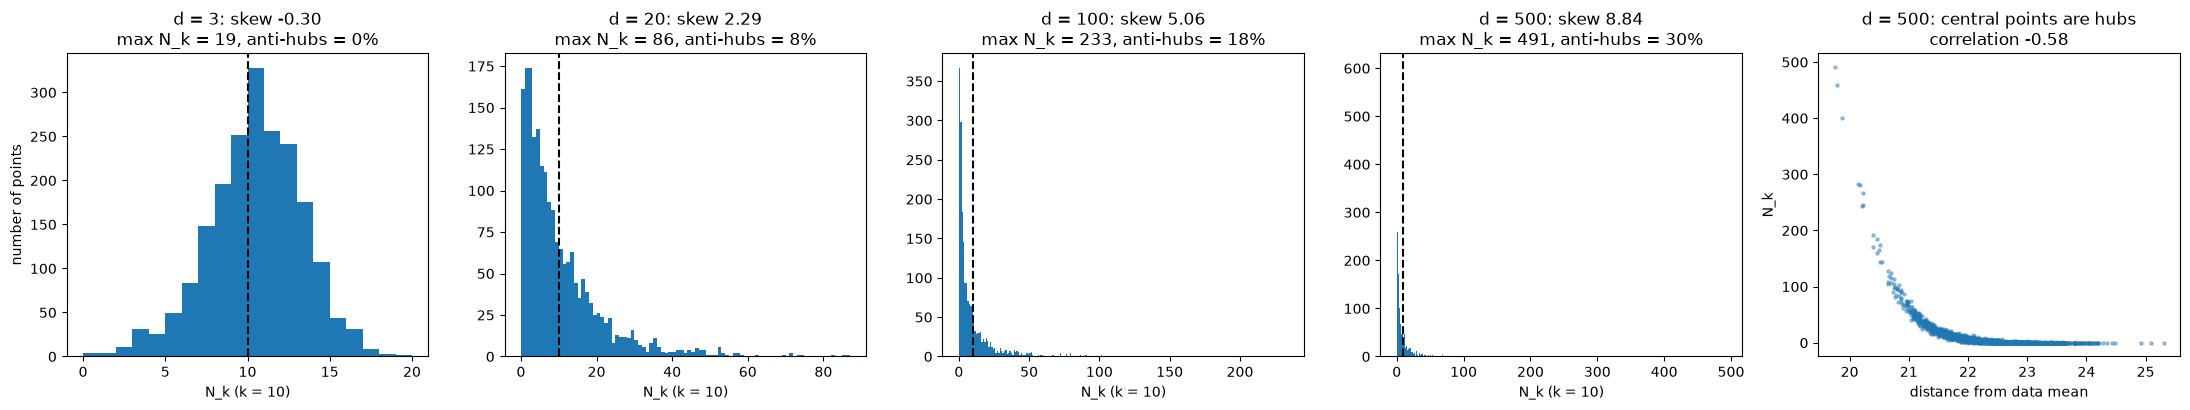

In [12]:
def k_occurrence(X, k):
    # N_k for every point: how many other points list it among their k nearest neighbors.
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)   # k+1 because each point's nearest is itself
    return np.bincount(idx[:, 1:].ravel(), minlength=len(X))            # drop column 0 (self), count appearances

rng = np.random.default_rng(SEED)                                       # fresh generator
K_HUB = 10                                                              # neighbors per point
hub_dims = [3, 20, 100, 500]                                            # dimensions to compare

fig, axes = plt.subplots(1, len(hub_dims) + 1, figsize=(22, 4.2))      # one histogram per d, plus one scatter
for ax, d in zip(axes, hub_dims):
    X = rng.standard_normal((2000, d))                                  # 2000 Gaussian points in d dimensions
    Nk = k_occurrence(X, K_HUB)                                         # k-occurrence of every point
    ax.hist(Nk, bins=range(0, Nk.max() + 2), color="tab:blue")          # one bar per possible count
    ax.axvline(K_HUB, color="k", ls="--")                               # the mean, always exactly k
    ax.set(title=f"d = {d}: skew {skew(Nk):.2f}\nmax N_k = {Nk.max()}, "
                 f"anti-hubs = {(Nk == 0).mean():.0%}",
           xlabel=f"N_k (k = {K_HUB})")
axes[0].set_ylabel("number of points")

# The last panel tests the math: at d = 500, is N_k related to distance from the center?
dist_center = np.linalg.norm(X - X.mean(axis=0), axis=1)               # each point's distance from the data mean
axes[-1].scatter(dist_center, Nk, s=5, alpha=0.4)                       # one dot per point
corr = np.corrcoef(dist_center, Nk)[0, 1]                               # Pearson correlation
axes[-1].set(xlabel="distance from data mean", ylabel="N_k",
             title=f"d = {hub_dims[-1]}: central points are hubs\ncorrelation {corr:.2f}")
plt.tight_layout()
plt.show()

**How to read it:**
- At `d = 3`, $N_k$ is spread fairly symmetrically around $k = 10$. Most points are somebody's neighbor about 10 times.
- As $d$ grows, the distribution develops a long right tail (rising skewness). A few hubs appear in the neighbor lists of a large number of points, while a growing share of anti-hubs appear in nobody's list.
- The scatter plot confirms the derivation: the closer a point is to the center, the larger its $N_k$ (strong negative correlation).

**What it means for KNN:** a test point's vote is dominated by whichever hubs happen to be nearby. A single mislabeled or atypical hub can corrupt the predictions of many test points, and anti-hub training points never influence any prediction at all.

## 8. The escape hatch: intrinsic dimension

**Objective:** Explain why KNN still works on many high-dimensional real datasets (images, text embeddings). The key is distinguishing **how many columns** the data has from **how many directions it actually varies in**.

**Key concepts:**
- **Ambient dimension:** the number of columns, $D$.
- **Intrinsic dimension:** the number of independent directions along which the data really varies. Data with intrinsic dimension 2 sitting in 500 columns lies on (or near) a 2-D surface inside the 500-D space.
- **The manifold hypothesis:** real high-dimensional data (images, audio, language) tends to lie near low-dimensional structures. A 64×64 photo of a face has 4096 pixels, but faces vary along far fewer directions: pose, lighting, expression, identity.

### The math: rotations don't change distances

Embed 2-D data in $D$ dimensions by padding it with zeros, then multiply by a random **orthogonal matrix** $Q$ (a rotation, possibly with reflections: a $D\times D$ matrix with $Q^\top Q = I$). The 2-D data is now smeared across all $D$ columns. But for any two points,

$$\lVert Qx - Qy\rVert^2 = (x-y)^\top Q^\top Q\,(x-y) = (x-y)^\top (x-y) = \lVert x - y \rVert^2.$$

**Every pairwise distance is exactly preserved**, so KNN, which only sees distances, behaves *identically*. 500 columns, zero curse. The damage in Sections 5–7 came from data that **varies independently in many directions**, not from having many columns.

In [13]:
rng = np.random.default_rng(SEED)                                # fresh generator
X2, y2 = make_moons(n_samples=1000, noise=0.2, random_state=SEED)   # 2-D moons: intrinsic dimension 2
X2 = StandardScaler().fit_transform(X2)                          # standardize both features to mean 0, std 1

D = 500                                                          # ambient dimension to embed into
X_pad = np.hstack([X2, np.zeros((len(X2), D - 2))])              # append 498 columns of zeros: shape (1000, 500)
Q, _ = np.linalg.qr(rng.standard_normal((D, D)))                 # QR decomposition of a random matrix gives a random orthogonal Q
X_rot = X_pad @ Q.T                                              # rotate every point: the signal is now spread over all 500 columns

print("Q is orthogonal (Q^T Q = I):", np.allclose(Q.T @ Q, np.eye(D)))
print("columns with non-zero values: before", np.sum(np.abs(X_pad).sum(0) > 1e-9),
      "| after", np.sum(np.abs(X_rot).sum(0) > 1e-9))             # 2 columns before, all 500 after
print("largest change in any pairwise distance:", f"{np.abs(pdist(X2) - pdist(X_rot)).max():.2e}")   # ~1e-14: rounding error only

knn = KNeighborsClassifier(n_neighbors=15)                       # the same KNN for both
print(f"KNN accuracy in 2-D:   {cross_val_score(knn, X2, y2, cv=5).mean():.3f}")
print(f"KNN accuracy in 500-D: {cross_val_score(knn, X_rot, y2, cv=5).mean():.3f}")

Q is orthogonal (Q^T Q = I): True
columns with non-zero values: before 2 | after 500
largest change in any pairwise distance: 4.88e-15
KNN accuracy in 2-D:   0.963
KNN accuracy in 500-D: 0.963


Identical accuracy, as the math demands. Now add **isotropic noise**, a small random wiggle in *every* one of the 500 directions, with standard deviation $\sigma$. The intrinsic dimension stops being 2:

In [14]:
rng = np.random.default_rng(SEED)                                 # fresh generator
for sigma in [0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]:               # noise levels (compare with the signal's std of 1)
    X_noisy = X_rot + sigma * rng.standard_normal(X_rot.shape)    # add N(0, sigma^2) noise to all 500 columns
    acc = cross_val_score(KNeighborsClassifier(n_neighbors=15), X_noisy, y2, cv=5).mean()
    total_noise = sigma * np.sqrt(D)                              # typical length of the noise vector: sqrt(500) * sigma
    print(f"sigma = {sigma:.2f} per direction (noise vector length ≈ {total_noise:4.2f}): accuracy {acc:.3f}")

sigma = 0.00 per direction (noise vector length ≈ 0.00): accuracy 0.963
sigma = 0.02 per direction (noise vector length ≈ 0.45): accuracy 0.965
sigma = 0.05 per direction (noise vector length ≈ 1.12): accuracy 0.958
sigma = 0.10 per direction (noise vector length ≈ 2.24): accuracy 0.944
sigma = 0.20 per direction (noise vector length ≈ 4.47): accuracy 0.884
sigma = 0.30 per direction (noise vector length ≈ 6.71): accuracy 0.835
sigma = 0.50 per direction (noise vector length ≈ 11.18): accuracy 0.790


Per direction, even $\sigma = 0.1$ looks tiny next to a signal spread of 1. But there are 500 directions, and the noise vector's length is $\sigma\sqrt{D}$ (the √d rule again): about 2.2 for $\sigma = 0.1$, already larger than a typical signal vector (length about $\sqrt{2} \approx 1.4$ for 2 standardized features). Accuracy holds up while the total noise is small, then falls steadily as it grows past the size of the signal. **What matters is the total noise across all directions compared with the signal.** That's the real enemy, not the column count.

### Measuring intrinsic dimension with PCA

PCA finds the orthogonal directions of greatest variance. The **explained variance ratio** of each component is the share of the total variance along it. If a handful of components explain almost everything, the data is effectively low-dimensional, whatever its column count.

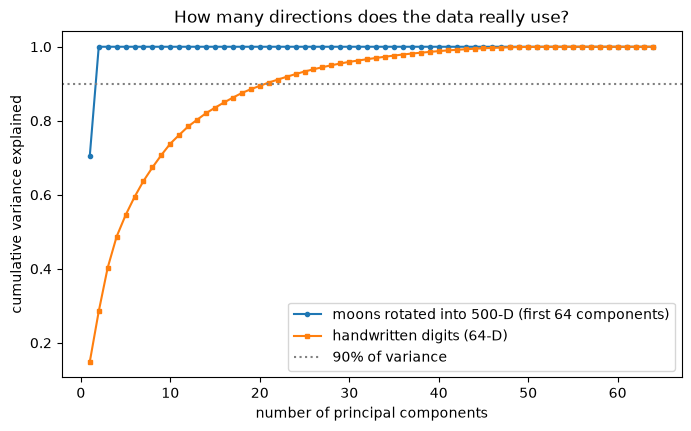

components needed for 90% of variance:
  rotated moons (500 columns): 2
  digits (64 columns):         21


In [15]:
digits = load_digits()                                            # 1797 handwritten digits, each an 8x8 image = 64 pixel features
X_dig, y_dig = digits.data, digits.target                         # X: (1797, 64) pixel intensities 0-16; y: the digit 0-9

pca_rot = PCA().fit(X_rot)                                        # PCA on the rotated 500-D moons
pca_dig = PCA().fit(X_dig)                                        # PCA on the 64-D digits
cum_rot = np.cumsum(pca_rot.explained_variance_ratio_)            # cumulative share of variance explained
cum_dig = np.cumsum(pca_dig.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, 65), cum_rot[:64], "o-", ms=3, label="moons rotated into 500-D (first 64 components)")
ax.plot(np.arange(1, 65), cum_dig, "s-", ms=3, label="handwritten digits (64-D)")
ax.axhline(0.9, color="gray", ls=":", label="90% of variance")
ax.set(xlabel="number of principal components", ylabel="cumulative variance explained",
       title="How many directions does the data really use?")
ax.legend()
plt.show()

print("components needed for 90% of variance:")
print("  rotated moons (500 columns):", np.searchsorted(cum_rot, 0.9) + 1)   # first index where cumulative share >= 0.9
print("  digits (64 columns):        ", np.searchsorted(cum_dig, 0.9) + 1)

The rotated moons need 2 components, recovering their true intrinsic dimension from 500 columns. The digits use 64 columns but have about 21 effective directions, and KNN does very well on them (Section 9). That's typical of real data: structured, low intrinsic dimension, and correlated features, which is much friendlier than the independent noise of Sections 4–6.

## 9. Defenses in practice

**Objective:** Apply what we've learned: bury real data in noise features, then try the standard defenses and see which work and why.

**The defenses:**
- **Feature selection** (supervised): score each feature by how strongly it relates to the label and keep the best ones. Here we use `SelectKBest(f_classif)`, which ranks features with an ANOVA F-test: how different the feature's mean is across classes, relative to its spread within classes. It uses the labels, so it can tell signal from noise directly.
- **PCA** (unsupervised): keep the top principal components, the directions of greatest variance. It never sees the labels. It helps only if **the signal has more variance than the noise** in the directions it keeps.
- Both go inside a **pipeline**, so they're fitted on each training fold only (no leakage into the cross-validation scores).

In [16]:
rng = np.random.default_rng(SEED)                                  # fresh generator
noise_sd = X_dig.std(axis=0).mean()                                # average pixel std, so noise is on the same scale as the pixels
X_dig_noisy = np.hstack([X_dig,                                    # the 64 real pixel features...
                         rng.normal(0, noise_sd, size=(len(X_dig), 500))])   # ...plus 500 noise features
print(f"noise std {noise_sd:.2f} (same as an average pixel); data shape now {X_dig_noisy.shape}")

knn = KNeighborsClassifier(n_neighbors=5)                          # one KNN configuration for all experiments
configs = {                                                        # name -> (model, data)
    "64 real pixels only":                    (knn, X_dig),
    "+ 500 noise features":                   (knn, X_dig_noisy),
    "+ noise, then SelectKBest(64)":          (make_pipeline(SelectKBest(f_classif, k=64), knn), X_dig_noisy),
    "+ noise, then PCA(20)":                  (make_pipeline(PCA(n_components=20, random_state=SEED), knn), X_dig_noisy),
}
import warnings                                                    # to silence one harmless warning below
with warnings.catch_warnings():                                    # warning filters apply only inside this block
    # A few border pixels are 0 in every image. Their F-test divides 0 by 0, and scikit-learn warns,
    # then ranks those pixels last, which is exactly right. So the warning is safe to ignore here.
    warnings.simplefilter("ignore")
    for name, (model, data) in configs.items():                    # evaluate each configuration
        acc = cross_val_score(model, data, y_dig, cv=5).mean()     # mean 5-fold CV accuracy (10 classes: chance = 0.10)
        print(f"{name:<34} accuracy {acc:.3f}")

noise std 3.68 (same as an average pixel); data shape now (1797, 564)
64 real pixels only                accuracy 0.963


+ 500 noise features               accuracy 0.843
+ noise, then SelectKBest(64)      accuracy 0.963
+ noise, then PCA(20)              accuracy 0.923


**How to read it:**
- With only the real pixels, KNN is excellent. Adding 500 noise features costs a lot of accuracy, exactly the mechanism of Section 6.
- **Feature selection** recovers almost everything: the F-test easily tells informative pixels from noise, because it uses the labels.
- **PCA** recovers most of the loss here. The digits' variance is concentrated in a few strong directions (Section 8), while the noise is spread thinly over 500 directions, so the top components are dominated by signal. If the noise had more variance per direction than the signal, PCA would keep the *noise* instead, so check before relying on it. (The lab notebook, Part 2, constructs exactly that failure case.)

**Other defenses worth knowing:**
- **Metric learning** (e.g. scikit-learn's `NeighborhoodComponentsAnalysis`): learn a linear transformation of the features so that distances reflect the labels. It's a learned, weighted distance for KNN.
- **Domain-appropriate representations:** for text or images, use learned embeddings whose distances are meaningful (and often cosine distance rather than Euclidean).
- **Approximate nearest neighbors** (FAISS, HNSW): these address *speed* in high dimensions, not the meaningfulness of distances.
- **A model that weights features**, when there's no reason to insist on KNN.

## 10. Summary

### The formulas

| Effect | Key formula | What it means for KNN |
|---|---|---|
| The √d rule | sum of $d$ independent terms: mean $\propto d$, sd $\propto \sqrt{d}$, sd/mean $\propto 1/\sqrt{d}$ | The engine behind almost everything below |
| Neighborhood size | edge to capture fraction $r$: $e_d(r) = r^{1/d}$ | "Local" neighborhoods span most of each feature's range |
| Volume in corners | $V_d(\tfrac12) = \dfrac{\pi^{d/2}}{\Gamma(d/2+1)\,2^d} \to 0$ | Data sits far from the center, near the edges |
| Thin shells | share in outer $\varepsilon$: $1 - (1-\varepsilon)^d \to 1$; Gaussian: $\lVert x\rVert \approx \sqrt{d} \pm 0.71$ | All points roughly equidistant from the center |
| Nearest-neighbor distance | $\rho_\text{NN} \propto n^{-1/d}$; halving it needs $2^d\times$ the data | More data can't realistically keep neighbors close |
| Distance concentration | uniform cube: $\mathbb{E}[D] \approx \sqrt{d/6}$, $\operatorname{sd}(D) \approx 0.24$, so $\operatorname{sd}/\text{mean} \approx 0.59/\sqrt{d}$ | Nearest and farthest become indistinguishable (Beyer et al., 1999) |
| Signal vs. noise | $P(\text{same class nearer}) \approx \Phi\big(g/\sqrt{v_0 + 12m}\big)$ | Each noise feature adds variance, never signal: SNR $\propto 1/\sqrt{m}$ |
| Hubness | $\mathbb{E}_y\lVert x-y\rVert^2 = \lVert x-\bar\mu\rVert^2 + \text{const}$ | Central points dominate the votes; outer points never vote |
| Rotation invariance | $\lVert Qx - Qy\rVert = \lVert x - y\rVert$ for orthogonal $Q$ | Column count alone is harmless; intrinsic dimension and noise matter |

### The one-paragraph version

KNN trusts distances. A squared distance is a sum over features, so by the √d rule its mean grows faster than its spread. In high dimensions, all distances become nearly equal, and the nearest neighbor is barely nearer than a random point. When only a few features carry signal, every irrelevant feature adds variance to every distance comparison while adding nothing to the gap between classes, so KNN's accuracy decays toward chance at rate $1/\sqrt{m}$. But the curse is about **independent variation in many directions**, not column count: data with low intrinsic dimension (most real data) can live in thousands of columns and still suit KNN, especially after feature selection or dimensionality reduction removes the noise.

### Exercises

1. **Section 5, by hand:** repeat the derivation for Gaussian data ($x_j, y_j \sim \mathcal{N}(0,1)$). Show that $(x_j - y_j)^2 = 2\chi^2_1$, so $\mu = 2$ and $\sigma^2 = 8$, and find the constants in $\mathbb{E}[D] \approx \sqrt{2d}$ and $\operatorname{sd}(D) \approx 1$. Verify by simulation.
2. **Section 6:** change the noise features' standard deviation from 1 to $\tau$. Redo the variance calculation (you should get $12\tau^4 m$) and check the new theory curve. How much do you need to shrink $\tau$ to tolerate 10× more noise features?
3. **Section 6:** add a second signal feature. How does $g$ change, and how much more noise can KNN tolerate before dropping to the same accuracy?
4. **Section 7:** repeat the hubness experiment with `metric="cosine"` in `NearestNeighbors`. Does hubness get better or worse?
5. **Section 9:** construct a case where PCA *fails* to rescue KNN. (Hint: give the noise features a larger standard deviation than the pixels.)

**Next:** `01_knn_high_dim.ipynb`, the lab, where you run these experiments yourself and predict the results before seeing them.